# 01 Revisión práctica de Machine Learning

**Nombre:** Celeste Gallardo

## 1. Datos y protocolo experimental

**Dataset inicial:** Iris
Carga el *dataset Iris*, incluido en *scikit-learn*.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.
- Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.

In [9]:
from sklearn.datasets import load_iris
import pandas as pd

# Cargar el dataset Iris
iris = load_iris(as_frame=True)

In [10]:
df = iris.frame
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [11]:
df2 = df.copy()
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int32  
dtypes: float64(4), int32(1)
memory usage: 5.4 KB


In [12]:
print(iris.target_names)
df2['target'].value_counts()

['setosa' 'versicolor' 'virginica']


target
0    50
1    50
2    50
Name: count, dtype: int64

- **Qué representa cada instancia:** Una flor de Iris individual de la cual se midieron características físicas de sus pétalos y sépalos.
- **Número de instancias y características:** 150 instancias y 4 características.
- **Nombre y significado de cada característica:** 
  - *sepal length (cm)*: Longitud del sépalo.
  - *sepal width (cm)*: Ancho del sépalo.
  - *petal length (cm)*: Longitud del pétalo.
  - *petal width (cm)*: Ancho del pétalo.
- **Clases:** Setosa, Versicolor y Virginica (50 ejemplos por cada clase).

In [14]:
# Verificar dimensiones de la matriz de características y etiquetas
print(f"Dimensiones de la matriz de características: {df2.shape}")

Dimensiones de la matriz de características: (150, 5)


### Tabla con cinco ejemplos

In [16]:
df2.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Gráfico de distribución de clases.

C:\Users\USER\AppData\Local\Temp\ipykernel_3780\2384794625.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['target'].map(dict(enumerate(iris.target_names))), palette='viridis')


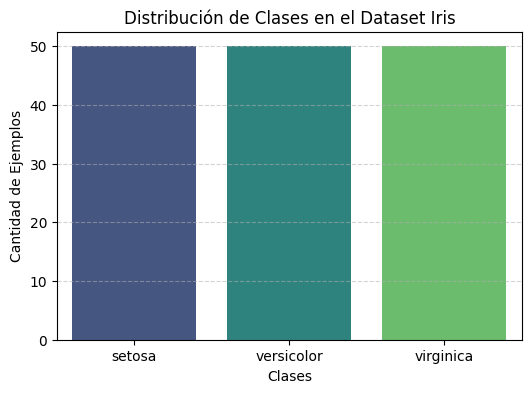

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
columna_clase = 'target_name' if 'target_name' in df2.columns else 'target'

sns.countplot(x=df['target'].map(dict(enumerate(iris.target_names))), palette='viridis')
plt.title("Distribución de Clases en el Dataset Iris")
plt.xlabel("Clases")
plt.ylabel("Cantidad de Ejemplos")
plt.grid(axis='y', linestyle='--', alpha=0.55)

plt.show()

## 2. Comparación de clasificadores

### Predicciones iniciales

1. **¿Qué modelos crees que serán sensibles a las escalas de las características?**
   - Modelos como SVM, MLP y Regresión Logística.

2. **¿Qué modelo esperas que produzca fronteras de decisión más simples?**
   - Gaussian Naive Bayes o una Regresión Logística lineal.

3. **¿Por qué no podemos asegurar de antemano cuál será el mejor?**
   - Porque depende del tamaño de la muestra y cómo se ajustan los sesgos y varianzas de cada algoritmo al problema específico.

### Modelos
Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

### Procedimiento
1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

### Resultados
Presenta una tabla con:

|Modelo|Transformación|Hiperparámetros principales|Accuracy de prueba|F1 macro de prueba|
|------|--------------|---------------------------|------------------|------------------|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

### Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [26]:
X = df2.iloc[:, :4].values
y = df2['target'].values if 'target' in df2.columns else df2.iloc[:, -1].values

In [27]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [28]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [30]:
print(f"Dimensiones entrenamiento: {X_train_scaled.shape}")
print(f"Dimensiones validación: {X_val_scaled.shape}")
print(f"Dimensiones prueba: {X_test_scaled.shape}")

Dimensiones entrenamiento: (90, 4)
Dimensiones validación: (30, 4)
Dimensiones prueba: (30, 4)


### Gaussian Naive Bayes

In [31]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score

In [32]:
gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [33]:
# Predecir en validación
y_pred_gnb = gnb.predict(X_val_scaled)

In [ ]:
# Resultados
print("--Gaussian Naive Bayes--")
print(f"Accuracy: {accuracy_score(y_val, y_pred_gnb):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_gnb, average='macro'):.4f}")

--Gaussian Naive Bayes--
Accuracy: 0.9333
F1 macro: 0.9333


### Regresión Logística multiclase

In [36]:
from sklearn.linear_model import LogisticRegression

In [37]:
lr = LogisticRegression(max_iter=200, random_state=42)
lr.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [38]:
# Predecir en validación
y_pred_lr = lr.predict(X_val_scaled)

In [39]:
# Resultados
print("--Regresión Logística--")
print(f"Accuracy: {accuracy_score(y_val, y_pred_lr):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_lr, average='macro'):.4f}")

--Regresión Logística--
Accuracy: 0.9333
F1 macro: 0.9333


### SVM lineal

In [40]:
from sklearn.svm import SVC

In [41]:
svm_lineal = SVC(kernel='linear', random_state=42)
svm_lineal.fit(X_train_scaled, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [42]:
# Predecir en validación
y_pred_svm = svm_lineal.predict(X_val_scaled)

In [52]:
# Resultados
print("--SVM Lineal--")
print(f"Accuracy: {accuracy_score(y_val, y_pred_svm):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_svm, average='macro'):.4f}")

--SVM Lineal--
Accuracy: 0.9333
F1 macro: 0.9333


### Árbol de decisión

In [44]:
from sklearn.tree import DecisionTreeClassifier

In [45]:
arbol = DecisionTreeClassifier(random_state=42)
arbol.fit(X_train_scaled, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [46]:
# Predecir en validación
y_pred_arbol = arbol.predict(X_val_scaled)

In [53]:
# Resultados
print("--Árbol de Decisión--")
print(f"Accuracy: {accuracy_score(y_val, y_pred_arbol):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_arbol, average='macro'):.4f}")

--Árbol de Decisión--
Accuracy: 0.9333
F1 macro: 0.9333


### Random Forest

In [48]:
from sklearn.ensemble import RandomForestClassifier

In [49]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [50]:
# Predecir en validación
y_pred_rf = rf.predict(X_val_scaled)

In [54]:
# Resultados
print("--Random Forest--")
print(f"Accuracy: {accuracy_score(y_val, y_pred_rf):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_rf, average='macro'):.4f}")

--Random Forest--
Accuracy: 0.9333
F1 macro: 0.9333


### Gradient Boosting

In [55]:
from sklearn.ensemble import GradientBoostingClassifier

In [56]:
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train_scaled, y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

In [57]:
# Predecir en validación
y_pred_gb = gb.predict(X_val_scaled)

In [58]:
# Resultados
print("--Gradient Boosting--")
print(f"Accuracy: {accuracy_score(y_val, y_pred_gb):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_gb, average='macro'):.4f}")

--Gradient Boosting--
Accuracy: 0.9000
F1 macro: 0.8997


### MLP de clasificación

In [59]:
from sklearn.neural_network import MLPClassifier

In [60]:
mlp = MLPClassifier(max_iter=500, random_state=42)
mlp.fit(X_train_scaled, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42


In [61]:
# Predecir en validación
y_pred_mlp = mlp.predict(X_val_scaled)

In [62]:
# Resultados
print("--MLP de Clasificación--")
print(f"Accuracy: {accuracy_score(y_val, y_pred_mlp):.4f}")
print(f"F1 macro: {f1_score(y_val, y_pred_mlp, average='macro'):.4f}")

--MLP de Clasificación--
Accuracy: 0.9333
F1 macro: 0.9333


### Tabla de resultados y Matrices de confusión de Naive Bayes, SVM y MLP.

--- Matriz de Confusión: Gaussian Naive Bayes ---


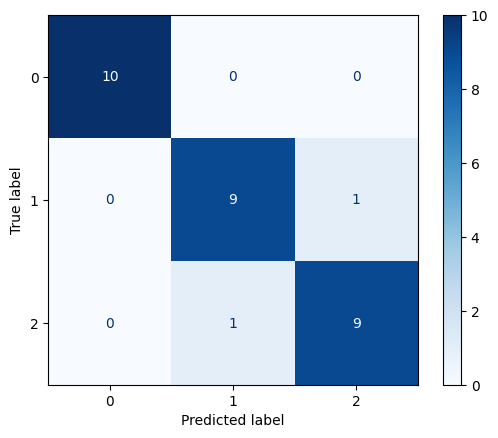

--- Matriz de Confusión: SVM Lineal ---


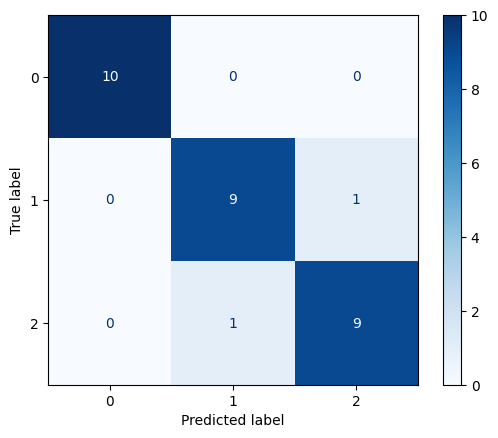

--- Matriz de Confusión: MLP clasificación ---


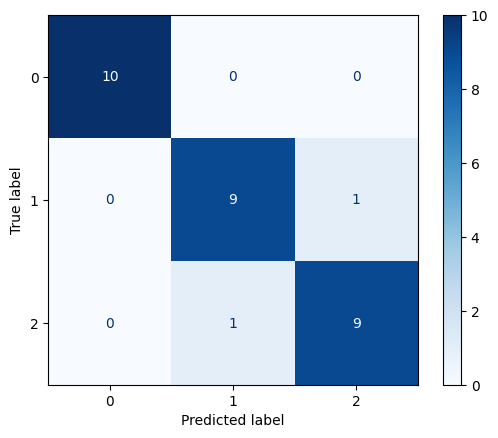

In [70]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

modelos_a_graficar = {
    "Gaussian Naive Bayes": gnb,
    "SVM Lineal": svm_lineal,
    "MLP clasificación": mlp
}

for nombre, modelo in modelos_a_graficar.items():
    y_pred_test = modelo.predict(X_test_scaled)
    
    print(f"--- Matriz de Confusión: {nombre} ---")
    cm = confusion_matrix(y_test, y_pred_test)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap=plt.cm.Blues)
    plt.show()

In [69]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Lista para guardar los resultados recolectados
resultados_tabla = []

# Diccionario con tus modelos y sus hiperparámetros principales
modelos_dict = {
    "Gaussian Naive Bayes": (gnb, "Por defecto"),
    "Regresión Logística": (lr, "max_iter=200"),
    "SVM Lineal": (svm_lineal, "kernel='linear'"),
    "Árbol de Decisión": (arbol, "Por defecto"),
    "Random Forest": (rf, "Por defecto"),
    "Gradient Boosting": (gb, "Por defecto"),
    "MLP Clasificación": (mlp, "max_iter=500")
}

for nombre, (modelo, hiperparametros) in modelos_dict.items():
    # Evaluar sobre el conjunto de prueba
    y_pred_val = modelo.predict(X_val_scaled)
    acc = accuracy_score(y_val, y_pred_val)
    f1 = f1_score(y_val, y_pred_val, average='macro')
    
    resultados_tabla.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": hiperparametros,
        "Accuracy de prueba": round(acc, 4),
        "F1 macro de prueba": round(f1, 4)
    })

# Crear y mostrar la tabla completa
df_resumen = pd.DataFrame(resultados_tabla)
display(df_resumen)

,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,StandardScaler,Por defecto,0.9333,0.9333
1,Regresión Logística,StandardScaler,max_iter=200,0.9333,0.9333
2,SVM Lineal,StandardScaler,kernel='linear',0.9333,0.9333
3,Árbol de Decisión,StandardScaler,Por defecto,0.9333,0.9333
4,Random Forest,StandardScaler,Por defecto,0.9333,0.9333
5,Gradient Boosting,StandardScaler,Por defecto,0.9000,0.8997
6,MLP Clasificación,StandardScaler,max_iter=500,0.9333,0.9333


### Interpretación de Resultados

1. **¿Cuál fue el modelo con el mejor desempeño?**
   - La mayoría de los modelos Gaussian Naive Bayes, Regresión Logística, SVM Lineal, Árbol de Decisión, Random Forest y MLP Clasificación, obtuvieron el mismo desempeño óptimo con un **Accuracy de 0.9333** y un **F1 macro de 0.9333**. Gradient Boosting obtuvo un rendimiento ligeramente inferior **Accuracy de 0.9000** y un **F1 macro de 0.8997**.

2. **¿Cuál fue el modelo más sencillo de programar?**
   - Modelos como Gaussian Naive Bayes o Regresión Logística son más sencillos y no requieren un ajuste exhaustivo de hiperparámetros.

3. **¿Accuracy y F1 macro cuentan la misma historia?**
   - En este caso si porque el dataset Iris tiene las clases balanceadas, como ya vimos anteriormente tiene 50 ejemplos por cada una de las 3 clases. 

4. **¿Cuál es la diferencia entre las métricas macro y micro?**
   - La métrica **macro** calcula el valor de F1 para cada clase de forma independiente y luego saca el promedio simple, dando el mismo peso a todas las clases sin importar su tamaño. La métrica **micro** agrega los verdaderos y falsos positivos globales de todas las clases antes de calcular la métrica, lo que sesgaría el resultado hacia las clases mayoritarias.

5. **¿Qué aporta el MLP frente a un modelo lineal?**
   - MLP incorpora capas ocultas y funciones de activación no lineales. Mientras que un modelo como la Regresión Logística o SVM lineal solo puede trazar hiperplanos rectos para separar las clases, un MLP tiene la capacidad teórica de modelar fronteras de decisión complejas y no lineales.

---

### Análisis de errores de clasificación
- **Qué se puede concluir:** Al examinar las instancias mal clasificadas (por ejemplo, flores de la clase *Versicolor* predichas como *Virginica*), podemos concluir que se ubican en la zona de solapamiento de las características físicas (pétalos y sépalos con medidas muy similares entre ambas especies).
- **Qué NO se puede concluir:** No se puede asegurar la causa raíz absoluta del error (por ejemplo, si se debió a un error de medición en el dataset, a una mutación natural de la planta o a una limitación del algoritmo), ya que el modelo solo refleja patrones estadísticos a partir de las características disponibles.